# Stage 1b: Preprocess WELFake

**Stage:** 1 (preprocessing) · **Runs on:** Kaggle and locally

| | |
|---|---|
| Input | `WELFake_Dataset.csv` (full news articles: title + text) |
| Output | `welfake_cleaned.csv` (the only file saved; tables and plots are shown in this notebook) |
| Used for | Task A classification, Task C clustering |

The full cleaned dataset is saved here. Downsampling (so WELFake does not dominate the merged
data) happens in Stage 2.

In [1]:
# Setup: import the shared code. Works on Kaggle and locally.
import sys
from pathlib import Path

# Locally, misinfo_utils.py is in <project>/src/. On Kaggle it is an attached Utility Script,
# so this loop finds nothing and the import below still works.
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "src" / "misinfo_utils.py").exists():
        sys.path.insert(0, str(folder / "src"))
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import misinfo_utils as mu

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 100)
paths = mu.setup("01b")

misinfo_utils | stage 01b | running on local
  read from : D:\misinfo-project\data\raw, D:\misinfo-project\outputs
  write to  : D:\misinfo-project\outputs\01_preprocess


In [2]:
MIN_WORDS = 5
WELFAKE_REAL_LABEL = "auto"   # which RAW label means real: "auto" (checked below), 0 or 1

## 1. Load

In [3]:
raw = pd.read_csv(mu.find_file("WELFake_Dataset.csv"))
print(raw.shape)
print("Columns:", list(raw.columns))
print("\nMissing values (%):")
print((raw.isna().mean() * 100).round(2))
print("\nRaw label counts:", raw["label"].value_counts().to_dict())

(72134, 4)
Columns: ['Unnamed: 0', 'title', 'text', 'label']

Missing values (%):
Unnamed: 0    0.00
title         0.77
text          0.05
label         0.00
dtype: float64

Raw label counts: {1: 37106, 0: 35028}


## 2. Build the text

Missing titles/texts are filled with an empty string **before** joining, otherwise one missing
part makes the whole text missing. A **space** separates title and text so words are not glued
together.

In [4]:
text = (raw["title"].fillna("").astype(str) + " " + raw["text"].fillna("").astype(str)).str.strip()
print("Rows with no text at all:", (text == "").sum())

Rows with no text at all: 0


## 3. Which raw label means "real"?

The documentation says `0 = fake, 1 = real`, but its own counts (35,028 real, 37,106 fake) point
the other way. The content decides: Reuters is a real news agency, so the label whose articles
mention Reuters far more often is the **real** one. Quote these numbers in the report.

In [5]:
has_reuters = text.str.contains("reuters", case=False)
reuters_check = pd.DataFrame({
    "rows": raw["label"].value_counts().sort_index(),
    "% mentioning Reuters": (has_reuters.groupby(raw["label"]).mean() * 100).round(1),
})
display(reuters_check)

if WELFAKE_REAL_LABEL == "auto":
    real_label = int(reuters_check["% mentioning Reuters"].idxmax())
else:
    real_label = int(WELFAKE_REAL_LABEL)
print(f"Raw label {real_label} = REAL -> becomes 0 (reliable); the other label becomes 1 (misleading)")

# Read a few openings to confirm by eye
for lab in sorted(raw["label"].unique()):
    print(f"\n--- raw label {lab} ---")
    for t in text[raw["label"] == lab].head(4):
        print("  ", t[:110])

,rows,% mentioning Reuters
label,,
0,35028,61.8
1,37106,1.8


Raw label 0 = REAL -> becomes 0 (reliable); the other label becomes 1 (misleading)

--- raw label 0 ---
   Bobby Jindal, raised Hindu, uses story of Christian conversion to woo evangelicals for potential 2016 bid A do
   May Brexit offer would hurt, cost EU citizens - EU parliament BRUSSELS (Reuters) - British Prime Minister Ther
   Schumer calls on Trump to appoint official to oversee Puerto Rico relief WASHINGTON (Reuters) - Charles Schume
   No Change Expected for ESPN Political Agenda Despite Huge Subscriber Decline - Breitbart As more and more spor

--- raw label 1 ---
   LAW ENFORCEMENT ON HIGH ALERT Following Threats Against Cops And Whites On 9-11By #BlackLivesMatter And #FYF91
   Did they post their votes for Hillary already?
   UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MOST CHARLOTTE RIOTERS WERE “PEACEFUL” PROTESTERS…In Her Home Stat
   SATAN 2: Russia unvelis an image of its terrifying new ‘SUPERNUKE’ – Western world takes notice The RS-28 Sarm


In [6]:
welfake = pd.DataFrame({
    "row_id": mu.make_row_ids(len(raw), "welfake"),
    "text": text,
    "label": (raw["label"] != real_label).astype(int),   # 0 reliable, 1 misleading
})
welfake["label"].value_counts()

label
1    37106
0    35028
Name: count, dtype: int64

## 4. Clean and remove duplicates

`clean_text` removes source giveaways such as `WASHINGTON (Reuters) -`, `21st Century Wire` and
`Featured image via ...`, so models learn from the content instead of the publisher.

In [7]:
welfake_clean, log = mu.clean_and_deduplicate(welfake, MIN_WORDS, target_col="label")
welfake_clean = mu.to_clean_schema(welfake_clean, "welfake")
pd.Series(log, name="rows").to_frame()

,rows
loaded,72134
after_missing_target,72134
after_empty_text,72125
after_min_length,72050
after_conflict_removal,72050
after_dedup,63313


## 5. Checks after cleaning

In [8]:
after = pd.DataFrame({
    "rows": welfake_clean["label"].value_counts().sort_index(),
    "% still mentioning Reuters": (welfake_clean["text"].str.contains("reuters", case=False)
                                   .groupby(welfake_clean["label"]).mean() * 100).round(2),
    "mean words": welfake_clean.groupby("label")["n_words"].mean().round(1),
    "median words": welfake_clean.groupby("label")["n_words"].median(),
}).rename(index=mu.LABEL_NAMES)
after   # Reuters should be ~0%; a big length gap between classes is a possible shortcut

,rows,% still mentioning Reuters,mean words,median words
label,,,,
reliable,34514,0.0,582.9,430.0
misleading,28799,0.0,511.3,385.0


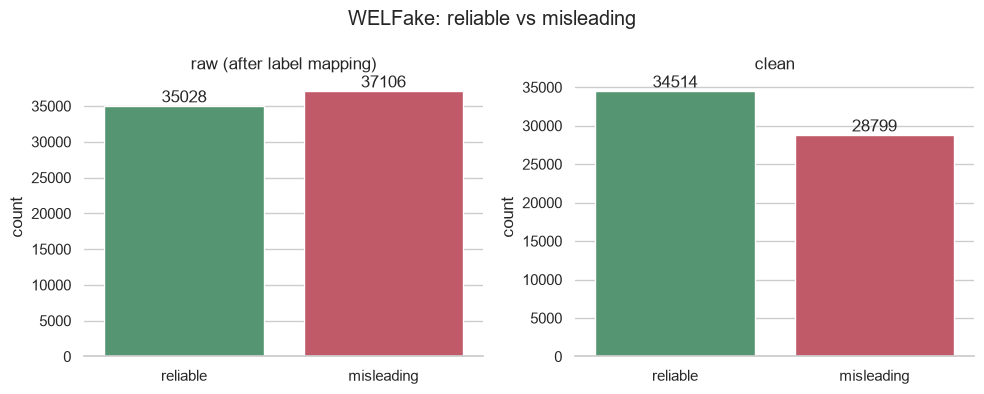

In [9]:
mu.plot_label_counts({"raw (after label mapping)": welfake, "clean": welfake_clean},
                     "WELFake: reliable vs misleading")

## 6. Save

In [10]:
mu.save_clean_dataset(welfake_clean, "welfake")
welfake_clean.head()

Saved 63,313 rows -> D:\misinfo-project\outputs\01_preprocess\welfake_cleaned.csv


,row_id,text,label,score,source_dataset,sub_source,n_words,had_url
0,welfake_000000,LAW ENFORCEMENT ON HIGH ALERT Following Threats Against Cops And Whites On 9-11By And Terrorists...,1,<NA>,welfake,welfake,878,False
1,welfake_000001,Did they post their votes for Hillary already?,1,<NA>,welfake,welfake,8,False
2,welfake_000002,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MOST CHARLOTTE RIOTERS WERE “PEACEFUL” PROTESTERS…In...,1,<NA>,welfake,welfake,52,False
3,welfake_000003,"Bobby Jindal, raised Hindu, uses story of Christian conversion to woo evangelicals for potential...",0,<NA>,welfake,welfake,1337,False
4,welfake_000004,SATAN 2: Russia unvelis an image of its terrifying new ‘SUPERNUKE’ – Western world takes notice ...,1,<NA>,welfake,welfake,345,False


**Next stage:** `02_merge_and_split` reads this file. On Kaggle, save this notebook with
**Save Version → Save & Run All**, then add it as an input to `02_merge_and_split`.